<a href="https://colab.research.google.com/github/amsalu2212/Project/blob/main/inference_uncertainty.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Name: Amsalu Tessema Adgeh**
#**ID Number: 2026A8000929002**
# Data Science – Assignment 2: Inference and Uncertainty
**Github** **Link**: https://github.com/amsalu2212

**Goal.** Quantify uncertainty with simulation + inference instead of reporting a point estimate alone.


In [ ]:
import json, os, platform, subprocess, sys, time, hashlib, itertools
import numpy as np, pandas as pd, scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})

# ---- frozen configuration (mirrors PREREGISTRATION.md) ----
MASTER_SEED = 20261012
ALPHA       = 0.05
DELTA_STAR  = 0.4          # minimum meaningful effect, control-SD units
N_EXAMPLE   = 40           # per arm, worked example (deliberately below the 80%-power n)
DGP_VERSION = "dgp-v1"

ss = np.random.SeedSequence(MASTER_SEED)
SEEDS = ss.spawn(8)        # one independent child stream per section
def rng_for(k): return np.random.default_rng(SEEDS[k])

SUMMARY = {"master_seed": MASTER_SEED, "alpha": ALPHA, "delta_star": DELTA_STAR, "dgp_version": DGP_VERSION}
CHECKS = []                # independent-verification results (pass AND fail are retained)
def check(name, value, ok, note=""):
    CHECKS.append({"check": name, "value": float(value), "pass": bool(ok), "note": note})
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: {value:.4g} {note}")

def git_commit():
    try: return subprocess.check_output(["git", "rev-parse", "HEAD"], stderr=subprocess.DEVNULL).decode().strip()
    except Exception: return "n/a (not a git checkout)"

ENV = {"python": sys.version.split()[0], "numpy": np.__version__, "scipy": scipy.__version__, "pandas": pd.__version__,
       "matplotlib": matplotlib.__version__, "platform": platform.platform(), "git_commit_at_run": git_commit()}
SUMMARY["env"] = ENV
json.dump({"master_seed": MASTER_SEED, "entropy": ss.entropy, "children_spawn_keys": [list(s.spawn_key) for s in SEEDS]},
          open("results/seeds.json", "w"), indent=1)
print(json.dumps(ENV, indent=1))

{
 "python": "3.13.16",
 "numpy": "2.1.3",
 "scipy": "1.16.3",
 "pandas": "2.2.3",
 "matplotlib": "3.10.0",
 "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
 "git_commit_at_run": "n/a (not a git checkout)"
}


## Part 1 – Pre-defined question, estimand, hypotheses, minimum meaningful effect

| Item | Specification (frozen in `PREREGISTRATION.md`) |
|---|---|
| Question | Does the treatment shift the mean outcome relative to control? |
| Estimand | Δ = E[Y∣T] − E[Y∣C], in control-SD units |
| Hypotheses | H0: Δ = 0 vs H1: Δ ≠ 0, two-sided, α = 0.05 |
| Minimum meaningful effect | δ* = 0.4 SD |
| Design target | power ≥ 0.80 at Δ = δ* |
| Decision rule | "supported" ⇔ 95 % interval excludes 0; "compatible with meaningful effect" ⇔ upper limit ≥ δ* |

**Assumptions to be stressed:** A1 independence, A2 light tails / variance structure, A3 individual-level randomisation, A4 fixed n.

### Method note (short; full derivations in the PDF)
* Var(Δ̂) = σ_T²/n_T + σ_C²/n_C, so with equal n and σ: SE = σ√(2/n) and Δ̂ ~ N(Δ, 2σ²/n) under normality.
* Welch interval: Δ̂ ± t₁₋α/₂,ν · SE with Satterthwaite ν. Pooled-t assumes equal variances.
* Percentile bootstrap: resample each arm with replacement, take the α/2 and 1−α/2 quantiles of Δ̂*.
* Permutation test: under *exchangeability* (identical distributions) any relabelling is equally likely; p = (1 + #{|Δ*| ≥ |Δ̂|})/(B + 1).
* Power (equal n, σ): λ = Δ/(σ√(2/n)) = d√(n/2); power = 1 − F_nct(t_crit; ν, λ) + F_nct(−t_crit; ν, λ). It depends on (Δ, σ) **only through d = Δ/σ**.
* Cluster randomisation with k per cluster and ICC ρ: Var(Δ̂) = 2σ²[1+(k−1)ρ]/(mk); ignoring this understates SE by √DE.

In [ ]:
# ---------- estimators (vectorised over replicates where possible) ----------
def welch_batch(T, C, alpha=ALPHA):
    """T: (R,nT), C: (R,nC). Returns diff, se, df, lo, hi, p."""
    nT, nC = T.shape[1], C.shape[1]
    vT, vC = T.var(1, ddof=1) / nT, C.var(1, ddof=1) / nC
    d, se = T.mean(1) - C.mean(1), np.sqrt(vT + vC)
    df = (vT + vC) ** 2 / (vT ** 2 / (nT - 1) + vC ** 2 / (nC - 1))
    tc = stats.t.ppf(1 - alpha / 2, df)
    return d, se, df, d - tc * se, d + tc * se, 2 * stats.t.sf(np.abs(d / se), df)

def pooled_batch(T, C, alpha=ALPHA):
    nT, nC = T.shape[1], C.shape[1]
    sp2 = ((nT - 1) * T.var(1, ddof=1) + (nC - 1) * C.var(1, ddof=1)) / (nT + nC - 2)
    d, se, df = T.mean(1) - C.mean(1), np.sqrt(sp2 * (1 / nT + 1 / nC)), nT + nC - 2
    tc = stats.t.ppf(1 - alpha / 2, df)
    return d, se, df, d - tc * se, d + tc * se, 2 * stats.t.sf(np.abs(d / se), df)

def boot_dist(t, c, rng, B):
    it = rng.integers(0, len(t), (B, len(t))); ic = rng.integers(0, len(c), (B, len(c)))
    return t[it].mean(1) - c[ic].mean(1)

def boot_percentile(t, c, rng, B=2000, alpha=ALPHA):
    return np.quantile(boot_dist(t, c, rng, B), [alpha / 2, 1 - alpha / 2])

def perm_p(t, c, rng, B=5000):
    z = np.concatenate([t, c]); nT = len(t)
    idx = rng.random((B, len(z))).argsort(1)[:, :nT]
    s = z[idx].sum(1)
    dperm = s / nT - (z.sum() - s) / len(c)
    obs = t.mean() - c.mean()
    return (1 + np.sum(np.abs(dperm) >= abs(obs) - 1e-12)) / (B + 1)

_COMBO = {}
def exact_cluster_perm_p_batch(TC, CC):
    """Exact permutation test on cluster means; TC,CC: (R,m). Enumerates all C(2m,m) label splits."""
    m = TC.shape[1]; allc = np.concatenate([TC, CC], 1)
    if m not in _COMBO: _COMBO[m] = np.array(list(itertools.combinations(range(2 * m), m)))
    idx = _COMBO[m]
    s = allc[:, idx].sum(2)                                   # (R, n_splits)
    dperm = s / m - (allc.sum(1, keepdims=True) - s) / m
    obs = (TC.mean(1) - CC.mean(1))[:, None]
    return (np.abs(dperm) >= np.abs(obs) - 1e-12).mean(1)

def power_analytic(delta, sigma, n, alpha=ALPHA):
    df = 2 * n - 2; lam = delta / (sigma * np.sqrt(2 / n)); tc = stats.t.ppf(1 - alpha / 2, df)
    return 1 - stats.nct.cdf(tc, df, lam) + stats.nct.cdf(-tc, df, lam)

### Independent verification of the hand-written estimators against SciPy
(Checks are recorded as PASS/FAIL; a FAIL would be kept in the log, not deleted.)

In [ ]:
rng = rng_for(0)
x, y = rng.normal(0.4, 1, 40), rng.normal(0, 1, 40)
d, se, df, lo, hi, p = welch_batch(x[None], y[None])
ref = stats.ttest_ind(x, y, equal_var=False)
check("V1 Welch p vs scipy.ttest_ind", abs(p[0] - ref.pvalue), abs(p[0] - ref.pvalue) < 1e-10, "(abs diff)")
ci_ref = ref.confidence_interval(0.95)
check("V1b Welch CI limits vs scipy", max(abs(lo[0] - ci_ref.low), abs(hi[0] - ci_ref.high)),
      max(abs(lo[0] - ci_ref.low), abs(hi[0] - ci_ref.high)) < 1e-10, "(abs diff)")

mine = boot_percentile(x, y, rng, B=20000)
sp = stats.bootstrap((x, y), lambda a, b, axis: a.mean(axis) - b.mean(axis), vectorized=True, n_resamples=20000,
                     method="percentile", rng=np.random.default_rng(1)).confidence_interval
dev = max(abs(mine[0] - sp.low), abs(mine[1] - sp.high))
check("V2 bootstrap CI vs scipy.stats.bootstrap (B=20000 each)", dev, dev < 0.03, "(max endpoint diff; MC tolerance 0.03)")

pm = perm_p(x, y, rng, B=20000)
pr = stats.permutation_test((x, y), lambda a, b, axis: a.mean(axis) - b.mean(axis), vectorized=True, n_resamples=20000,
                            rng=np.random.default_rng(2)).pvalue
tol = 4 * np.sqrt(0.25 / 20000)
check("V3 permutation p vs scipy.stats.permutation_test", abs(pm - pr), abs(pm - pr) < tol, f"(tolerance {tol:.4f})")

# exact cluster permutation sanity: all-equal labels give p = 1
check("V3b exact permutation returns p=1 for zero effect data", exact_cluster_perm_p_batch(np.zeros((1, 6)), np.zeros((1, 6)))[0] - 1,
      exact_cluster_perm_p_batch(np.zeros((1, 6)), np.zeros((1, 6)))[0] == 1.0, "(p-1)")

[PASS] V1 Welch p vs scipy.ttest_ind: 5.551e-17 (abs diff)
[PASS] V1b Welch CI limits vs scipy: 5.551e-17 (abs diff)
[PASS] V2 bootstrap CI vs scipy.stats.bootstrap (B=20000 each): 0.006186 (max endpoint diff; MC tolerance 0.03)
[PASS] V3 permutation p vs scipy.stats.permutation_test: 0.00275 (tolerance 0.0141)
[PASS] V3b exact permutation returns p=1 for zero effect data: 0 (p-1)


## Part 2 – Simulation of the sampling distribution of Δ̂
20 000 replicate experiments per sample size, baseline DGP: Y_T ~ N(Δ,1), Y_C ~ N(0,1), Δ = δ* = 0.4.

 n_per_arm  mean_of_Dhat  sim_SE  theory_SE=sqrt(2/n)  rel_err_%
        10        0.4069  0.4475               0.4472     0.0620
        20        0.3982  0.3170               0.3162     0.2303
        40        0.4003  0.2244               0.2236     0.3493
        80        0.4003  0.1568               0.1581    -0.8376
       160        0.4000  0.1124               0.1118     0.4994
       320        0.4004  0.0788               0.0791    -0.3370
[PASS] V5 SE scaling slope on log-log (theory -0.5): -0.501 
[PASS] V5b max relative SE error vs sqrt(2/n), %: 0.8376 (MC SE of an SD ≈ 0.5%)


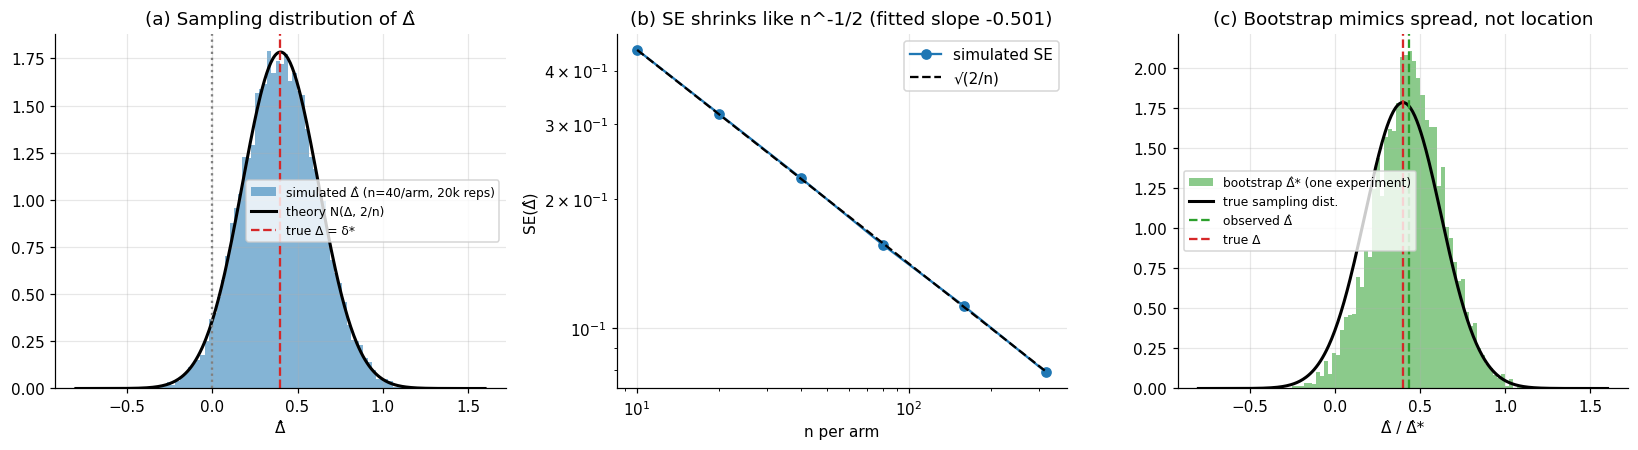

In [ ]:
rng = rng_for(1); R = 20000; NS = [10, 20, 40, 80, 160, 320]
sim_sd, sim_mean = {}, {}
for n in NS:
    T = rng.normal(DELTA_STAR, 1, (R, n)); C = rng.normal(0, 1, (R, n))
    dh = T.mean(1) - C.mean(1); sim_sd[n], sim_mean[n] = dh.std(ddof=1), dh.mean()
    if n == N_EXAMPLE: DH40 = dh
th_sd = {n: np.sqrt(2 / n) for n in NS}
tab = pd.DataFrame({"n_per_arm": NS, "mean_of_Dhat": [sim_mean[n] for n in NS], "sim_SE": [sim_sd[n] for n in NS],
                    "theory_SE=sqrt(2/n)": [th_sd[n] for n in NS]}); tab["rel_err_%"] = 100 * (tab.sim_SE / tab["theory_SE=sqrt(2/n)"] - 1)
print(tab.round(4).to_string(index=False)); tab.to_csv("results/sampling_distribution.csv", index=False)
slope = np.polyfit(np.log(NS), np.log([sim_sd[n] for n in NS]), 1)[0]
check("V5 SE scaling slope on log-log (theory -0.5)", slope, abs(slope + 0.5) < 0.01)
check("V5b max relative SE error vs sqrt(2/n), %", tab["rel_err_%"].abs().max(), tab["rel_err_%"].abs().max() < 1.5, "(MC SE of an SD ≈ 0.5%)")
SUMMARY["sampling"] = {"R": R, "slope": float(slope), "se_n40_sim": float(sim_sd[40]), "se_n40_theory": float(th_sd[40]),
                       "shapiro_p_n40": float(stats.shapiro(DH40[:5000]).pvalue)}

# one observed experiment + its bootstrap distribution (used in Part 3 as well)
rng = rng_for(2)
xt, xc = rng.normal(DELTA_STAR, 1, N_EXAMPLE), rng.normal(0, 1, N_EXAMPLE)
bd = boot_dist(xt, xc, rng, 5000)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
g = np.linspace(-0.8, 1.6, 400)
ax[0].hist(DH40, bins=70, density=True, alpha=.55, label=f"simulated Δ̂ (n={N_EXAMPLE}/arm, 20k reps)")
ax[0].plot(g, stats.norm.pdf(g, DELTA_STAR, np.sqrt(2 / N_EXAMPLE)), "k", lw=2, label="theory N(Δ, 2/n)")
ax[0].axvline(0, c="grey", ls=":"); ax[0].axvline(DELTA_STAR, c="C3", ls="--", label="true Δ = δ*")
ax[0].set(title="(a) Sampling distribution of Δ̂", xlabel="Δ̂"); ax[0].legend(fontsize=8)
ax[1].loglog(NS, [sim_sd[n] for n in NS], "o-", label="simulated SE"); ax[1].loglog(NS, [th_sd[n] for n in NS], "k--", label="√(2/n)")
ax[1].set(title=f"(b) SE shrinks like n^-1/2 (fitted slope {slope:.3f})", xlabel="n per arm", ylabel="SE(Δ̂)"); ax[1].legend()
ax[2].hist(bd, bins=60, density=True, alpha=.55, color="C2", label="bootstrap Δ̂* (one experiment)")
ax[2].plot(g, stats.norm.pdf(g, DELTA_STAR, np.sqrt(2 / N_EXAMPLE)), "k", lw=2, label="true sampling dist.")
ax[2].axvline(xt.mean() - xc.mean(), c="C2", ls="--", label="observed Δ̂"); ax[2].axvline(DELTA_STAR, c="C3", ls="--", label="true Δ")
ax[2].set(title="(c) Bootstrap mimics spread, not location", xlabel="Δ̂ / Δ̂*"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/fig1_sampling_distribution.png", dpi=150); plt.show()
SUMMARY["sampling"].update({"boot_se_example": float(bd.std(ddof=1)), "obs_diff_example": float(xt.mean() - xc.mean())})

## Part 3 – Interval and test implementations on a worked example, then validated by repetition
**Worked example (n = 40/arm, true Δ = 0.4).** At n = 40 the design is *under-powered* (≈ 0.52, see Part 4) – chosen on purpose so that the
uncertainty is visible. One draw shows what an analyst would see; the repetition study shows what the intervals *promise*.

observed Δ̂ = 0.438  (true Δ = 0.4)
Welch   95% CI [0.023, 0.854]  p = 0.0391
Boot    95% CI [0.019, 0.834]  (percentile, B=2000)
Perm    p = 0.0400 (B=5000)
Pre-declared decision rule → supported & compatible with ≥MME


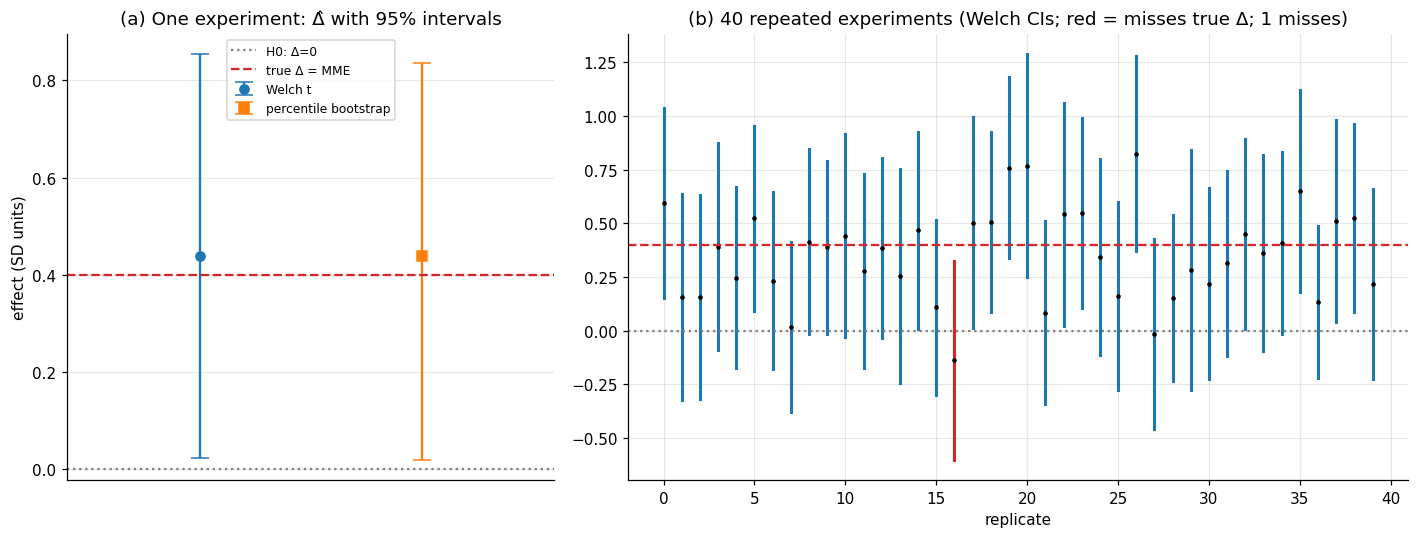

In [ ]:
d, se, df, lo, hi, p = [a[0] for a in welch_batch(xt[None], xc[None])]
bl, bh = boot_percentile(xt, xc, rng_for(3), B=2000)
pp = perm_p(xt, xc, rng_for(3), B=5000)
print(f"observed Δ̂ = {d:.3f}  (true Δ = {DELTA_STAR})")
print(f"Welch   95% CI [{lo:.3f}, {hi:.3f}]  p = {p:.4f}")
print(f"Boot    95% CI [{bl:.3f}, {bh:.3f}]  (percentile, B=2000)")
print(f"Perm    p = {pp:.4f} (B=5000)")
def classify(l, h):
    s, c = (l > 0 or h < 0), h >= DELTA_STAR
    return "supported & compatible with ≥MME" if s and c else "supported but possibly negligible" if s else "inconclusive/negligible"
print("Pre-declared decision rule →", classify(lo, hi))
SUMMARY["example"] = dict(diff=float(d), welch=[float(lo), float(hi)], welch_p=float(p), boot=[float(bl), float(bh)], perm_p=float(pp), verdict=classify(lo, hi))

# coverage illustration: 40 repeated experiments
rng = rng_for(3); K = 40; rows = []
for k in range(K):
    a, b = rng.normal(DELTA_STAR, 1, N_EXAMPLE), rng.normal(0, 1, N_EXAMPLE)
    w = welch_batch(a[None], b[None]); l2, h2 = boot_percentile(a, b, rng, B=1000)
    rows.append((a.mean() - b.mean(), w[3][0], w[4][0], l2, h2))
rows = np.array(rows)
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].errorbar([0], [d], yerr=[[d - lo], [hi - d]], fmt="o", capsize=6, label="Welch t"); ax[0].errorbar([1], [d], yerr=[[d - bl], [bh - d]], fmt="s", capsize=6, label="percentile bootstrap")
ax[0].axhline(0, c="grey", ls=":", label="H0: Δ=0"); ax[0].axhline(DELTA_STAR, c="C3", ls="--", label="true Δ = MME"); ax[0].set_xlim(-.6, 1.6); ax[0].set_xticks([])
ax[0].set(title="(a) One experiment: Δ̂ with 95% intervals", ylabel="effect (SD units)"); ax[0].legend(fontsize=8)
for k, (m, a1, b1, a2, b2) in enumerate(rows):
    miss = not (a1 <= DELTA_STAR <= b1)
    ax[1].plot([k, k], [a1, b1], c="C3" if miss else "C0", lw=2); ax[1].plot(k, m, "k.", ms=4)
ax[1].axhline(DELTA_STAR, c="C3", ls="--"); ax[1].axhline(0, c="grey", ls=":")
ax[1].set(title=f"(b) 40 repeated experiments (Welch CIs; red = misses true Δ; {int(sum(not(r[1]<=DELTA_STAR<=r[2]) for r in rows))} misses)", xlabel="replicate")
plt.tight_layout(); plt.savefig("figures/fig2_intervals.png", dpi=150); plt.show()

## Part 4 – How sample size, noise and effect size drive power
Grid: n ∈ {10,…,200} per arm × Δ ∈ {0,0.2,0.4,0.6,0.8} × σ ∈ {0.5,1,2}; 4 000 simulated experiments per cell (Welch test, α = 0.05).
Monte-Carlo SE of any power estimate ≤ 0.0079. Simulation is compared with the exact non-central-t power.

[PASS] V4 max |sim − exact| power over 120 cells: 0.01658 (4×MCSE = 0.0316; 120 cells so ~1 cell may exceed 3×MCSE)
[PASS] V4b mean |sim − exact|: 0.003504 
[PASS] V6 baseline type-I rate (mean over null cells): 0.04917 
n/arm for 80% power at Δ=δ*=0.4, σ=1: exact 100; simulated power at that n = 0.8031 (MCSE 0.0028)
power at the worked-example size n=40: exact 0.424
max spread of simulated power across (Δ,σ) pairs with equal d = Δ/σ: 0.0240


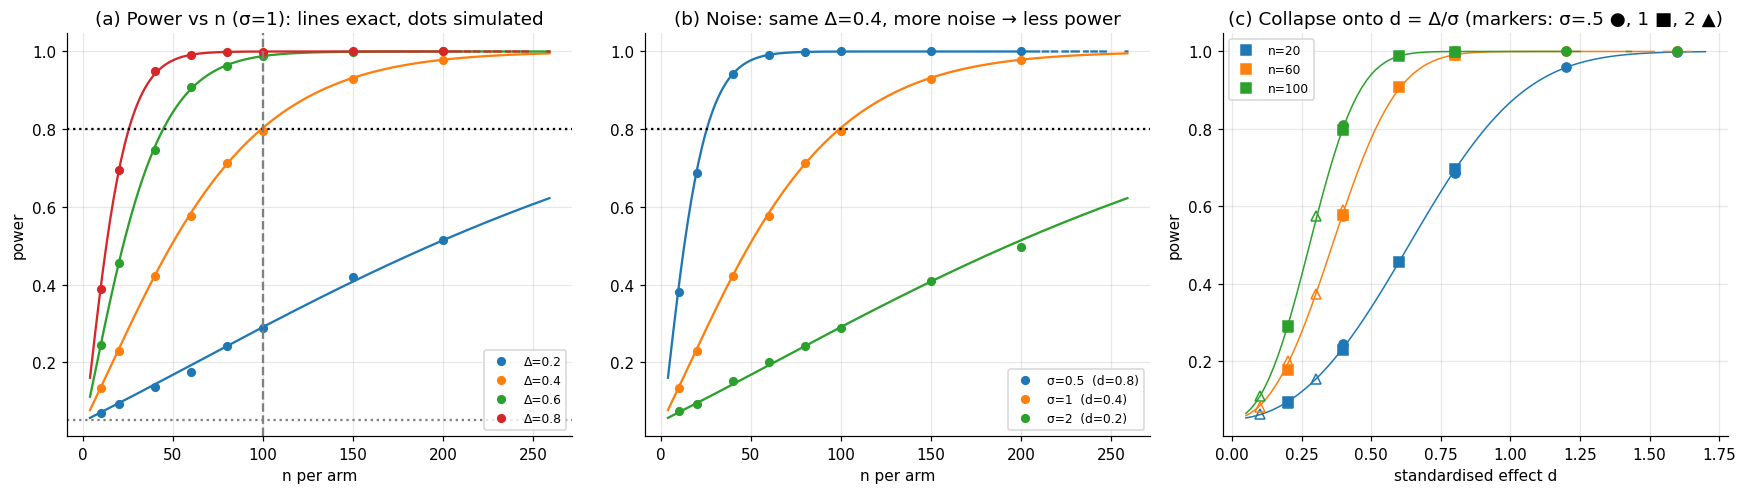

delta    0.0    0.2    0.4    0.6    0.8
n                                       
10     0.043  0.068  0.134  0.246  0.388
20     0.050  0.092  0.229  0.456  0.696
40     0.056  0.136  0.422  0.747  0.948
60     0.052  0.176  0.577  0.908  0.991
80     0.051  0.240  0.713  0.962  0.998
100    0.046  0.289  0.796  0.989  1.000
150    0.044  0.420  0.929  0.999  1.000
200    0.046  0.514  0.977  1.000  1.000


In [ ]:
rng = rng_for(4); RP = 4000
NG = [10, 20, 40, 60, 80, 100, 150, 200]; DG = [0, .2, .4, .6, .8]; SG = [.5, 1, 2]
rows = []
for s_ in SG:
    for dl in DG:
        for n in NG:
            T = rng.normal(dl, s_, (RP, n)); C = rng.normal(0, s_, (RP, n))
            pw = (welch_batch(T, C)[5] < ALPHA).mean()
            rows.append(dict(sigma=s_, delta=dl, n=n, d=dl / s_, power_sim=pw, power_exact=(power_analytic(dl, s_, n) if dl > 0 else ALPHA)))
P = pd.DataFrame(rows); P["abs_dev"] = (P.power_sim - P.power_exact).abs(); P.to_csv("results/power_grid.csv", index=False)
mcse_max = np.sqrt(.25 / RP)
check("V4 max |sim − exact| power over 120 cells", P.abs_dev.max(), P.abs_dev.max() < 4 * mcse_max, f"(4×MCSE = {4*mcse_max:.4f}; 120 cells so ~1 cell may exceed 3×MCSE)")
check("V4b mean |sim − exact|", P.abs_dev.mean(), P.abs_dev.mean() < 1.5 * mcse_max * 0.8)
null_rows = P[P.delta == 0]
check("V6 baseline type-I rate (mean over null cells)", null_rows.power_sim.mean(), abs(null_rows.power_sim.mean() - ALPHA) < 3 * np.sqrt(ALPHA * .95 / (RP * len(null_rows))))

# smallest n for 80% power at the MME (σ = 1), exact + confirmed by simulation
n_req = next(n for n in range(2, 1000) if power_analytic(DELTA_STAR, 1, n) >= 0.80)
rng = rng_for(5); RR = 20000
sim_req = (welch_batch(rng.normal(DELTA_STAR, 1, (RR, n_req)), rng.normal(0, 1, (RR, n_req)))[5] < ALPHA).mean()
print(f"n/arm for 80% power at Δ=δ*=0.4, σ=1: exact {n_req}; simulated power at that n = {sim_req:.4f} (MCSE {np.sqrt(.8*.2/RR):.4f})")
print(f"power at the worked-example size n={N_EXAMPLE}: exact {power_analytic(DELTA_STAR,1,N_EXAMPLE):.3f}")
# collapse check: power depends on (Δ,σ) only through d
g = P[P.delta > 0].groupby(["d", "n"]).power_sim.agg(["min", "max"]); g["spread"] = g["max"] - g["min"]
print(f"max spread of simulated power across (Δ,σ) pairs with equal d = Δ/σ: {g.spread.max():.4f}")
SUMMARY["power"] = dict(R_per_cell=RP, n_required=int(n_req), sim_power_at_n_required=float(sim_req), power_n40=float(power_analytic(DELTA_STAR, 1, N_EXAMPLE)),
                        max_dev=float(P.abs_dev.max()), mean_dev=float(P.abs_dev.mean()), collapse_spread=float(g.spread.max()),
                        type1_mean=float(null_rows.power_sim.mean()))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
nn = np.arange(4, 260)
for dl, col in zip([.2, .4, .6, .8], ["C0", "C1", "C2", "C3"]):
    q = P[(P.sigma == 1) & (P.delta == dl)]
    ax[0].plot(nn, [power_analytic(dl, 1, n) for n in nn], c=col, lw=1.5); ax[0].plot(q.n, q.power_sim, "o", c=col, ms=5, label=f"Δ={dl}")
ax[0].axhline(.8, c="k", ls=":"); ax[0].axvline(n_req, c="grey", ls="--"); ax[0].axhline(ALPHA, c="grey", ls=":")
ax[0].set(title="(a) Power vs n (σ=1): lines exact, dots simulated", xlabel="n per arm", ylabel="power"); ax[0].legend(fontsize=8)
for s_, col in zip(SG, ["C0", "C1", "C2"]):
    q = P[(P.delta == .4) & (P.sigma == s_)]
    ax[1].plot(nn, [power_analytic(.4, s_, n) for n in nn], c=col, lw=1.5); ax[1].plot(q.n, q.power_sim, "o", c=col, ms=5, label=f"σ={s_}  (d={0.4/s_:.1f})")
ax[1].axhline(.8, c="k", ls=":"); ax[1].set(title="(b) Noise: same Δ=0.4, more noise → less power", xlabel="n per arm"); ax[1].legend(fontsize=8)
q = P[(P.delta > 0) & (P.n.isin([20, 60, 100]))]
mk = {.5: "o", 1: "s", 2: "^"}
for n, col in zip([20, 60, 100], ["C0", "C1", "C2"]):
    for s_ in SG:
        z = q[(q.n == n) & (q.sigma == s_)]; ax[2].plot(z.d, z.power_sim, mk[s_], c=col, ms=6, mfc="none" if s_ == 2 else col, label=f"n={n}" if s_ == 1 else None)
    ax[2].plot(np.linspace(0.05, 1.7, 100), [power_analytic(x_, 1, n) for x_ in np.linspace(0.05, 1.7, 100)], c=col, lw=1)
ax[2].set(title="(c) Collapse onto d = Δ/σ (markers: σ=.5 ●, 1 ■, 2 ▲)", xlabel="standardised effect d", ylabel="power"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/fig3_power.png", dpi=150); plt.show()
print(P[(P.sigma == 1)].pivot(index="n", columns="delta", values="power_sim").round(3).to_string())

## Part 5 – Assumption-violating counter-examples
Four data-generating processes, each with the **same nominal 5 % procedure** applied, evaluated at the truth Δ = 0 (type-I rate) and Δ = 0.4 (power, CI coverage).
2 000 replicates per cell (MC SE of a 5 % rate ≈ 0.005); B = 1 000 resamples inside each replicate.

| Scenario | Violated assumption | Construction |
|---|---|---|
| S0 baseline | none | N(0,1), 40 vs 40 |
| S1 heavy tails | A2 (light tails) | Student-t, 2.5 df, rescaled to unit variance, 40 vs 40 |
| S2 unequal variance & n | A2 (variance structure) | treated: n=10, σ=3; control: n=70, σ=1 |
| **S3 clustered** | **A1 independence, A3 unit of randomisation** | 6 clusters/arm × 10 subjects, ICC ρ = 0.3, whole clusters randomised |

In [ ]:
RS = 2000; B_RS = 1000
def gen_S0(rng, R, dl): return rng.normal(dl, 1, (R, 40)), rng.normal(0, 1, (R, 40)), None
def gen_S1(rng, R, dl):
    f = 1 / np.sqrt(2.5 / 0.5); return dl + f * rng.standard_t(2.5, (R, 40)), f * rng.standard_t(2.5, (R, 40)), None
def gen_S2(rng, R, dl): return rng.normal(dl, 3, (R, 10)), rng.normal(0, 1, (R, 70)), None
M_CL, K_CL, RHO = 6, 10, 0.3
def gen_S3(rng, R, dl):
    sb, sw = np.sqrt(RHO), np.sqrt(1 - RHO)
    T = dl + rng.normal(0, sb, (R, M_CL, 1)) + rng.normal(0, sw, (R, M_CL, K_CL))
    C = rng.normal(0, sb, (R, M_CL, 1)) + rng.normal(0, sw, (R, M_CL, K_CL))
    return T.reshape(R, -1), C.reshape(R, -1), (T.mean(2), C.mean(2))
SCEN = {"S0 baseline": gen_S0, "S1 heavy tails": gen_S1, "S2 unequal var & n": gen_S2, "S3 clustered": gen_S3}

def evaluate(gen, rng, truth):
    T, C, cm = gen(rng, RS, truth)
    out = {}
    for name, fn in [("Welch t", welch_batch), ("Pooled t", pooled_batch)]:
        _, _, _, lo, hi, p = fn(T, C); out[name] = (p < ALPHA, (lo <= truth) & (truth <= hi))
    bl = np.array([boot_percentile(T[r], C[r], rng, B_RS) for r in range(RS)])
    out["Percentile bootstrap"] = (~((bl[:, 0] <= 0) & (0 <= bl[:, 1])), (bl[:, 0] <= truth) & (truth <= bl[:, 1]))
    pr = np.array([perm_p(T[r], C[r], rng, B_RS) for r in range(RS)])
    out["Permutation (mean diff)"] = (pr < ALPHA, None)
    if cm is not None:                                   # cluster-aware analyses on cluster means
        TC, CC = cm
        _, _, _, lo, hi, p = welch_batch(TC, CC); out["Cluster-mean Welch t"] = (p < ALPHA, (lo <= truth) & (truth <= hi))
        cb = np.array([boot_percentile(TC[r], CC[r], rng, B_RS) for r in range(RS)])
        out["Cluster bootstrap"] = (~((cb[:, 0] <= 0) & (0 <= cb[:, 1])), (cb[:, 0] <= truth) & (truth <= cb[:, 1]))
        out["Cluster permutation (exact)"] = (exact_cluster_perm_p_batch(TC, CC) < ALPHA, None)
    return out

t0 = time.time(); kids = SEEDS[6].spawn(2 * len(SCEN)); rows = []; j = 0
for sname, gen in SCEN.items():
    res0 = evaluate(gen, np.random.default_rng(kids[j]), 0.0); res1 = evaluate(gen, np.random.default_rng(kids[j + 1]), DELTA_STAR); j += 2
    for meth in res0:
        t1, power = res0[meth][0].mean(), res1[meth][0].mean()
        cov = res1[meth][1].mean() if res1[meth][1] is not None else np.nan
        rows.append(dict(scenario=sname, method=meth, type1=t1, power_at_MME=power, coverage_at_MME=cov,
                         mcse_type1=np.sqrt(max(t1 * (1 - t1), 1e-4) / RS)))
    print(f"{sname} done ({time.time()-t0:.0f}s)")
M = pd.DataFrame(rows); M.to_csv("results/scenario_matrix.csv", index=False)
print(M.round(3).to_string(index=False))

S0 baseline done (17s)
S1 heavy tails done (34s)
S2 unequal var & n done (50s)
S3 clustered done (71s)
          scenario                      method  type1  power_at_MME  coverage_at_MME  mcse_type1
       S0 baseline                     Welch t  0.040         0.414            0.949       0.004
       S0 baseline                    Pooled t  0.041         0.415            0.949       0.004
       S0 baseline        Percentile bootstrap  0.050         0.444            0.942       0.005
       S0 baseline     Permutation (mean diff)  0.042         0.416              NaN       0.004
    S1 heavy tails                     Welch t  0.046         0.588            0.962       0.005
    S1 heavy tails                    Pooled t  0.046         0.588            0.962       0.005
    S1 heavy tails        Percentile bootstrap  0.074         0.612            0.935       0.006
    S1 heavy tails     Permutation (mean diff)  0.050         0.600              NaN       0.005
S2 unequal var & n      

### The S3 counter-example in detail
Predicted inflation: DE = 1 + (k−1)ρ = 3.7 ⇒ the naive SE is too small by √DE ≈ 1.92. A normal-approximation prediction of the naive 5 % test's real type-I rate is 2[1 − Φ(1.96/√DE)].
Here 20 000 clustered null experiments are used for precision.

design effect DE = 3.70;  predicted naive type-I ≈ 0.308
naive Welch  type-I = 0.315   mean claimed SE = 0.178   true SD(Δ̂) = 0.349   ratio = 1.97 (√DE = 1.92)
cluster-mean Welch type-I = 0.046   mean claimed SE = 0.343
[PASS] V7 naive S3 type-I vs DE-based prediction: 0.007226 (sim 0.315 vs pred 0.308; normal approx ignores t-tails)
[PASS] V7b variance inflation ≈ DE: 0.03642 (relative error)

Illustration (replicate #0; TRUE Δ = 0; selected only because naive p<0.01 – an event with probability 0.185 here):
  naive Welch      Δ̂=0.727  95% CI [0.390, 1.065]  p=0.0000  → 'supported & compatible with ≥MME'
  cluster-mean t   Δ̂=0.727  95% CI [0.034, 1.421]  p=0.0415  → 'supported & compatible with ≥MME'
  exact cluster perm p = 0.0390


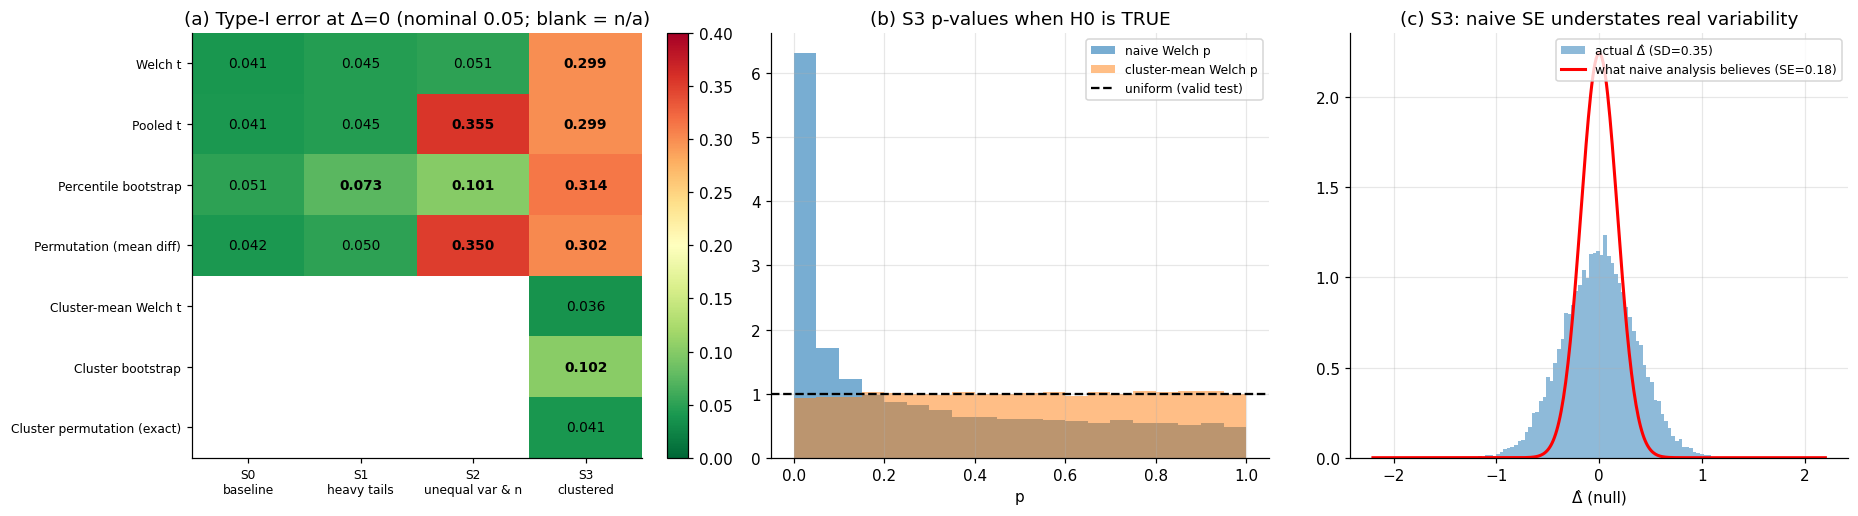

In [ ]:
rng = rng_for(7); R3 = 20000
T, C, (TC, CC) = gen_S3(rng, R3, 0.0)
dN, seN, dfN, loN, hiN, pN = welch_batch(T, C); dC, seC, dfC, loC, hiC, pC = welch_batch(TC, CC)
DE = 1 + (K_CL - 1) * RHO
pred = 2 * (1 - stats.norm.cdf(1.96 / np.sqrt(DE)))
t1N, t1C = (pN < ALPHA).mean(), (pC < ALPHA).mean()
print(f"design effect DE = {DE:.2f};  predicted naive type-I ≈ {pred:.3f}")
print(f"naive Welch  type-I = {t1N:.3f}   mean claimed SE = {seN.mean():.3f}   true SD(Δ̂) = {dN.std(ddof=1):.3f}   ratio = {dN.std(ddof=1)/seN.mean():.2f} (√DE = {np.sqrt(DE):.2f})")
print(f"cluster-mean Welch type-I = {t1C:.3f}   mean claimed SE = {seC.mean():.3f}")
check("V7 naive S3 type-I vs DE-based prediction", abs(t1N - pred), abs(t1N - pred) < 0.04, f"(sim {t1N:.3f} vs pred {pred:.3f}; normal approx ignores t-tails)")
check("V7b variance inflation ≈ DE", (dN.var(ddof=1) / (seN ** 2).mean()) / DE - 1, abs((dN.var(ddof=1) / (seN ** 2).mean()) / DE - 1) < 0.05, "(relative error)")

# illustrative single dataset: FIRST replicate in the seeded stream with naive p < 0.01 (screening rule fixed here, not tuned)
i0 = int(np.argmax(pN < 0.01))
print(f"\nIllustration (replicate #{i0}; TRUE Δ = 0; selected only because naive p<0.01 – an event with probability {(pN<0.01).mean():.3f} here):")
print(f"  naive Welch      Δ̂={dN[i0]:.3f}  95% CI [{loN[i0]:.3f}, {hiN[i0]:.3f}]  p={pN[i0]:.4f}  → '{classify(loN[i0], hiN[i0])}'")
print(f"  cluster-mean t   Δ̂={dC[i0]:.3f}  95% CI [{loC[i0]:.3f}, {hiC[i0]:.3f}]  p={pC[i0]:.4f}  → '{classify(loC[i0], hiC[i0])}'")
print(f"  exact cluster perm p = {exact_cluster_perm_p_batch(TC[i0:i0+1], CC[i0:i0+1])[0]:.4f}")
SUMMARY["cluster"] = dict(DE=float(DE), pred_type1=float(pred), naive_type1=float(t1N), cluster_mean_type1=float(t1C), R=R3,
    true_sd=float(dN.std(ddof=1)), claimed_se=float(seN.mean()), p_lt_01=float((pN < .01).mean()),
    illus=dict(rep=i0, naive_diff=float(dN[i0]), naive_ci=[float(loN[i0]), float(hiN[i0])], naive_p=float(pN[i0]),
               cl_ci=[float(loC[i0]), float(hiC[i0])], cl_p=float(pC[i0]),
               cl_perm_p=float(exact_cluster_perm_p_batch(TC[i0:i0+1], CC[i0:i0+1])[0]),
               naive_verdict=classify(loN[i0], hiN[i0]), cl_verdict=classify(loC[i0], hiC[i0])))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
meths = ["Welch t", "Pooled t", "Percentile bootstrap", "Permutation (mean diff)", "Cluster-mean Welch t", "Cluster bootstrap", "Cluster permutation (exact)"]
H = M.pivot(index="method", columns="scenario", values="type1").reindex(meths)[list(SCEN)]
im = ax[0].imshow(H.values, cmap="RdYlGn_r", vmin=0, vmax=.4, aspect="auto")
for (i, j), v in np.ndenumerate(H.values):
    if not np.isnan(v): ax[0].text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9, fontweight="bold" if v > .07 else None)
ax[0].set_xticks(range(4)); ax[0].set_xticklabels([s.replace(" ", "\n", 1) for s in H.columns], fontsize=8); ax[0].set_yticks(range(len(meths))); ax[0].set_yticklabels(meths, fontsize=8)
ax[0].grid(False); ax[0].set_title("(a) Type-I error at Δ=0 (nominal 0.05; blank = n/a)"); plt.colorbar(im, ax=ax[0], fraction=.046)
ax[1].hist(pN, bins=20, range=(0, 1), density=True, alpha=.6, label="naive Welch p"); ax[1].hist(pC, bins=20, range=(0, 1), density=True, alpha=.5, label="cluster-mean Welch p")
ax[1].axhline(1, c="k", ls="--", label="uniform (valid test)"); ax[1].set(title="(b) S3 p-values when H0 is TRUE", xlabel="p"); ax[1].legend(fontsize=8)
g = np.linspace(-2.2, 2.2, 400)
ax[2].hist(dN, bins=80, density=True, alpha=.5, label=f"actual Δ̂ (SD={dN.std():.2f})")
ax[2].plot(g, stats.norm.pdf(g, 0, seN.mean()), "r", lw=2, label=f"what naive analysis believes (SE={seN.mean():.2f})")
ax[2].set(title="(c) S3: naive SE understates real variability", xlabel="Δ̂ (null)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/fig4_counterexample.png", dpi=150); plt.show()

## Negative results, limitations, and what challenges the claims
The cell below prints findings that *cut against* a naive reading, computed from the saved results (nothing is hand-typed).

In [ ]:
def g_(s, m, c): return float(M[(M.scenario == s) & (M.method == m)][c].iloc[0])
print("1. Cluster bootstrap is NOT a cure with 6 clusters/arm: type-I =", round(g_("S3 clustered", "Cluster bootstrap", "type1"), 3),
      "vs cluster-mean t =", round(g_("S3 clustered", "Cluster-mean Welch t", "type1"), 3))
print("2. The valid cluster-aware test pays in power: power at MME =", round(g_("S3 clustered", "Cluster-mean Welch t", "power_at_MME"), 3),
      "vs naive (invalid) =", round(g_("S3 clustered", "Welch t", "power_at_MME"), 3))
print("3. Permutation test is not a test of means under unequal variances/n (S2): type-I =", round(g_("S2 unequal var & n", "Permutation (mean diff)", "type1"), 3),
      "; pooled t =", round(g_("S2 unequal var & n", "Pooled t", "type1"), 3), "; Welch =", round(g_("S2 unequal var & n", "Welch t", "type1"), 3))
print("4. Heavy tails (S1): Welch type-I =", round(g_("S1 heavy tails", "Welch t", "type1"), 3), ", coverage at MME =", round(g_("S1 heavy tails", "Welch t", "coverage_at_MME"), 3),
      "; power at MME =", round(g_("S1 heavy tails", "Welch t", "power_at_MME"), 3), "vs baseline", round(g_("S0 baseline", "Welch t", "power_at_MME"), 3))
print("5. Bootstrap at n=40 baseline: coverage =", round(g_("S0 baseline", "Percentile bootstrap", "coverage_at_MME"), 3), "vs Welch", round(g_("S0 baseline", "Welch t", "coverage_at_MME"), 3),
      "(percentile bootstrap is slightly liberal in small samples)")
print("6. Worked example is under-powered: exact power at n=40 =", round(SUMMARY["power"]["power_n40"], 3))
SUMMARY["matrix"] = M.round(4).to_dict(orient="records")

1. Cluster bootstrap is NOT a cure with 6 clusters/arm: type-I = 0.102 vs cluster-mean t = 0.036
2. The valid cluster-aware test pays in power: power at MME = 0.163 vs naive (invalid) = 0.58
3. Permutation test is not a test of means under unequal variances/n (S2): type-I = 0.35 ; pooled t = 0.355 ; Welch = 0.051
4. Heavy tails (S1): Welch type-I = 0.045 , coverage at MME = 0.963 ; power at MME = 0.588 vs baseline 0.414
5. Bootstrap at n=40 baseline: coverage = 0.942 vs Welch 0.949 (percentile bootstrap is slightly liberal in small samples)
6. Worked example is under-powered: exact power at n=40 = 0.424


## Verification ledger and manifest

In [ ]:
C_ = pd.DataFrame(CHECKS); print(C_.to_string(index=False)); C_.to_csv("results/verification_checks.csv", index=False)
SUMMARY["checks"] = CHECKS; SUMMARY["n_checks_failed"] = int((~C_["pass"]).sum())

# determinism check: re-draw the Part-2 worked example from the same child seed and compare bit-for-bit
r2 = rng_for(2); a, b = r2.normal(DELTA_STAR, 1, N_EXAMPLE), r2.normal(0, 1, N_EXAMPLE)
SUMMARY["deterministic_redraw_identical"] = bool(np.array_equal(a, xt) and np.array_equal(b, xc)); print("seed re-draw identical:", SUMMARY["deterministic_redraw_identical"])
json.dump(SUMMARY, open("results/summary.json", "w"), indent=1, default=float)
man = {f: hashlib.sha256(open(os.path.join(dp, f), "rb").read()).hexdigest() for dp in ["results", "figures"] for f in sorted(os.listdir(dp)) if f != "manifest_sha256.json"}
json.dump(man, open("results/manifest_sha256.json", "w"), indent=1); print(f"{len(man)} artefacts hashed; failed checks: {SUMMARY['n_checks_failed']}")

                                                  check         value  pass                                                      note
                          V1 Welch p vs scipy.ttest_ind  5.551115e-17  True                                                (abs diff)
                           V1b Welch CI limits vs scipy  5.551115e-17  True                                                (abs diff)
V2 bootstrap CI vs scipy.stats.bootstrap (B=20000 each)  6.185634e-03  True                    (max endpoint diff; MC tolerance 0.03)
       V3 permutation p vs scipy.stats.permutation_test  2.749863e-03  True                                        (tolerance 0.0141)
 V3b exact permutation returns p=1 for zero effect data  0.000000e+00  True                                                     (p-1)
           V5 SE scaling slope on log-log (theory -0.5) -5.009824e-01  True                                                          
              V5b max relative SE error vs sqrt(2/n), %  8.376